# Triplet accuracy against dimension for the pooled data

The figures of this notebook show, for the pooled data of O1 - O5 and for every pooled dataset of the pooling designs, the cross-validated test accuracy at 1 to 5 dimensions, in the format of the figures of the individual observers (`plots/triplet_accuracy_vs_dimensions_{obs}_annotated.pdf`). The notebook reads the saved cross-validation results of every fit.

In every panel, the line is the mean test accuracy over the 150 cross-validation folds (5 splits x 30 repeats) with error bars of 2 SD. The dashed vertical line marks the dimensionality under the significance criterion. Below the curve, the first row gives the mean accuracy at every dimension; for every step from $d$ to $d + 1$ dimensions, the rows below give the mean gain and the Holm-corrected p-value of the significance test. The gain and the p-value are bold when $p < 0.05$.

Datasets (see the notebooks named):

| dataset | construction | notebook |
|:--|:--|:--|
| pooled-5x | all data of O1 - O5 | `finding_dimensionality_aggregated_per_observer` |
| design A, scaled-down pool | a random fifth of every session of pooled-5x | `pooled_design_A_scaled_down_pool` |
| design B, crowd-like pool | the structure of one observer's data, every row answered three times by three different observers | `pooled_design_B_crowd_like_pool` |
| design C, mix obs | matched one-rep datasets (one session of each trial set), every row answered by one of the five observers | `pooled_design_C_matched_one_rep_datasets` |
| design C, single obs | the same one-rep datasets, answered by one observer as recorded | `pooled_design_C_matched_one_rep_datasets` |

One figure per design A and B shows all its draws, for all three image sets. For every image set, a further figure shows draw 0 of both designs and one mix obs dataset next to pooled-5x. Figures are saved in `../plots/pooled_accuracy_vs_dimension/`. The last sections print the summary tables: the mean dimensionality and the mean triplet accuracy of every dataset, by image set and task.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from io_json import read_json_dataclass
from pooling_plots import PALETTE_IMAGE_SET, draw_accuracy_panel
from utils import read_dimensionality


TASKS = ['classic', 'odd one out']
IMAGE_SETS = ['action', 'greebles', 'taxonomic']
OBSERVERS = ['O1', 'O2', 'O3', 'O4', 'O5']
TASK_TITLES = {'classic': 'Classic', 'odd one out': 'Odd one out'}
OUTPUT = '../plots/pooled_accuracy_vs_dimension'
os.makedirs(OUTPUT, exist_ok=True)

# design C: the 9 combinations (i, j) of the sessions of trial sets 1 and 2, and the draws of mix obs
C_COMBINATIONS = [(i, j) for i in range(1, 4) for j in range(1, 4)]
C_DRAWS = 5

# key: (label, json name with {draw}, {task} and {image_set}, draws, image sets)
DATASETS = {
    'pooled-5x': ('pooled-5x: all data of O1 - O5', 'pooled O1 - O5-{task}-{image_set}', [0], IMAGE_SETS),
    'design-A': ('design A: scaled-down pool', 'design-A-draw{draw}-{task}-{image_set}', range(10), IMAGE_SETS),
    'design-B': ('design B: crowd-like pool', 'design-B-draw{draw}-{task}-{image_set}', range(10), IMAGE_SETS),
    # design C: a 'draw' names the combination (i, j) and the draw, or the observer and the combination
    'design-C-mix-obs': ('design C, mix obs: matched one-rep datasets', 'design-C-mix-obs-{draw}-{task}-{image_set}',
                         [f'comb{i}{j}-draw{k}' for i, j in C_COMBINATIONS for k in range(C_DRAWS)], IMAGE_SETS),
    'design-C-single-obs': ('design C, single obs: matched one-rep datasets',
                            'design-C-single-obs-{draw}-{task}-{image_set}',
                            [f'{obs}-comb{i}{j}' for obs in OBSERVERS for i, j in C_COMBINATIONS], IMAGE_SETS),
}

`read_fit` reads the cross-validation results of one fit; `draw_panel` draws them (`pooling_plots.draw_accuracy_panel`).

In [2]:
def read_fit(key, draw, task, image_set):
    name = DATASETS[key][1].format(draw=draw, task=task, image_set=image_set)
    return read_json_dataclass(f'../data/triplet_accuracy_vs_dimensionality-{name}.json')


def draw_panel(ax, key, draw, task, image_set):
    dim_result = read_fit(key, draw, task, image_set)
    draw_accuracy_panel(ax, dim_result.test_scores, dim_result.dimensions, dim_result.estimated_dimension,
                        dim_result.stats_result['pvals_corrected'], PALETTE_IMAGE_SET[image_set])
    return dim_result.estimated_dimension

## One figure per design, all draws

Rows are the draws; columns are the tasks and image sets.

In [3]:
for key, (label, _, draws, image_sets) in DATASETS.items():
    if key == 'pooled-5x' or key.startswith('design-C'):
        continue
    columns = [(task, image_set) for image_set in image_sets for task in TASKS]
    fig, axes = plt.subplots(len(draws), len(columns), figsize=(3.5 * len(columns), 3 * len(draws)),
                             sharex=True, sharey=True, squeeze=False)
    for row, draw in enumerate(draws):
        for col, (task, image_set) in enumerate(columns):
            ax = axes[row, col]
            significance = draw_panel(ax, key, draw, task, image_set)
            title = f'{TASK_TITLES[task]}' + (f' / {image_set}' if len(image_sets) > 1 else '')
            ax.set_title(f"{title}  ({significance} dimension{'' if significance == 1 else 's'})", fontsize=9)
        axes[row, 0].set_ylabel(f'draw {draw}' if isinstance(draw, int) else draw, fontsize=9)
    fig.supylabel('Triplet accuracy (test set)')
    fig.supxlabel('Dimension')
    fig.suptitle(label, y=1.0)
    fig.tight_layout()
    fig.savefig(f'{OUTPUT}/{key}.pdf', bbox_inches='tight')
    plt.close(fig)
    print('saved', f'{OUTPUT}/{key}.pdf')

saved ../plots/pooled_accuracy_vs_dimension/design-A.pdf


saved ../plots/pooled_accuracy_vs_dimension/design-B.pdf


## Pooled-5x against the designs

Draw 0 of designs A and B and the first mix obs one-rep dataset of design C (combination 1-1, draw 0) next to pooled-5x, one figure per image set, saved to `../plots/pooled_accuracy_vs_dimension/pooled_5x_A_B_{image_set}.pdf`.

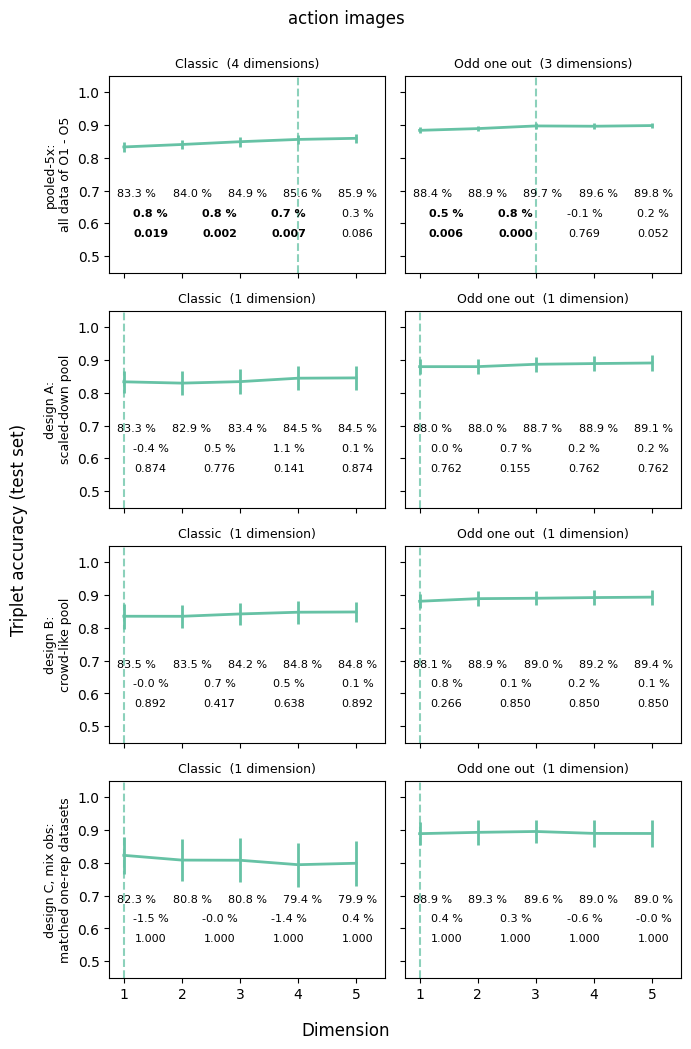

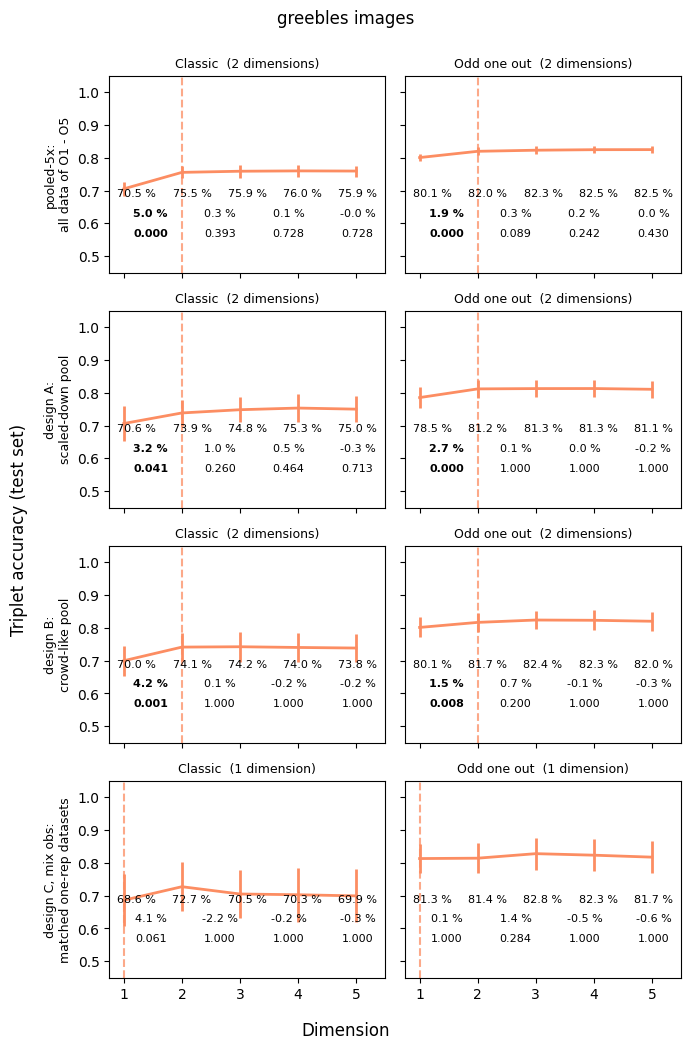

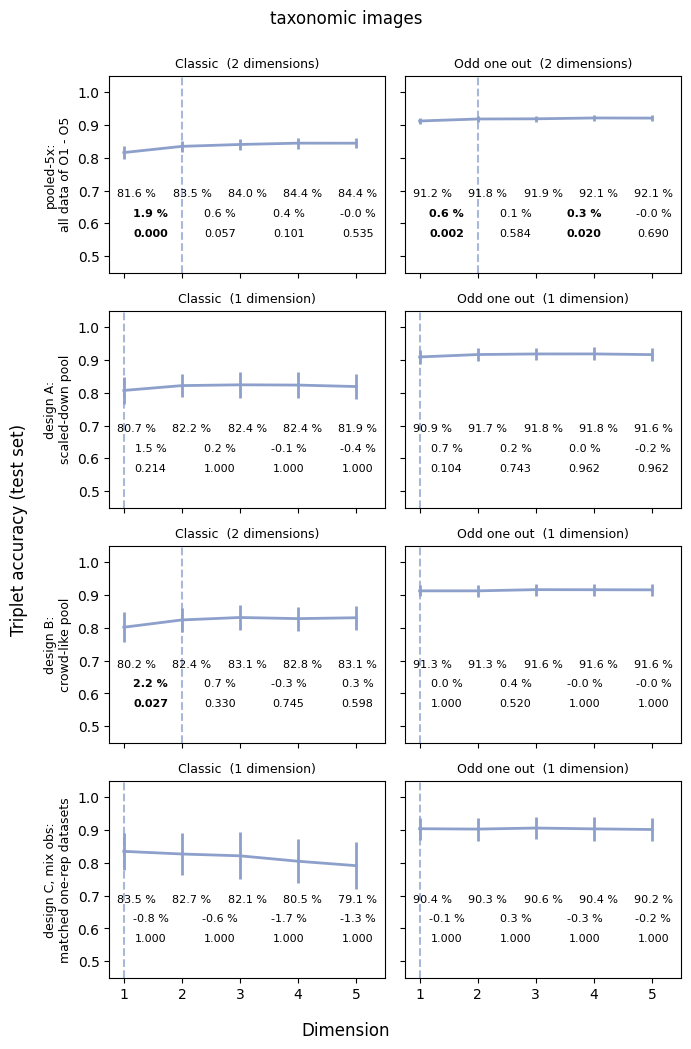

In [4]:
keys = ['pooled-5x', 'design-A', 'design-B', 'design-C-mix-obs']
for image_set in IMAGE_SETS:
    fig, axes = plt.subplots(len(keys), len(TASKS), figsize=(7, 2.6 * len(keys)), sharex=True, sharey=True)
    for row, key in enumerate(keys):
        for col, task in enumerate(TASKS):
            significance = draw_panel(axes[row, col], key, DATASETS[key][2][0], task, image_set)
            axes[row, col].set_title(f"{TASK_TITLES[task]}  ({significance} dimension{'' if significance == 1 else 's'})",
                                     fontsize=9)
        axes[row, 0].set_ylabel(DATASETS[key][0].replace(': ', ':\n'), fontsize=9)
    fig.supylabel('Triplet accuracy (test set)')
    fig.supxlabel('Dimension')
    fig.suptitle(f'{image_set} images', y=1.0)
    fig.tight_layout()
    fig.savefig(f'{OUTPUT}/pooled_5x_A_B_{image_set}.pdf', bbox_inches='tight')
    plt.show()

## Mean dimensionality of the designs

The mean dimensionality over the 10 draws of designs A and B and over the 45 datasets of each variant of design C, against pooled-5x (a single fit) and the mean of the five individual observers. The dimensionalities of the designs are read from their jsons, and checked against the `dimensionality` column of the csv tables of the fitting notebooks.

In [5]:
CSV = {'design-A': '../data/found-dimensionality-embeddings-design-A-draws.csv',
       'design-B': '../data/found-dimensionality-embeddings-design-B-draws.csv',
       'design-C-mix-obs': '../data/found-dimensionality-embeddings-design-C-draws.csv',
       'design-C-single-obs': '../data/found-dimensionality-embeddings-design-C-draws.csv'}

rows = []
for task in TASKS:
    for image_set in IMAGE_SETS:
        row = {'task': task, 'image set': image_set}
        for key in CSV:
            _, draws, image_sets = DATASETS[key][1:]
            if image_set not in image_sets:
                row[key] = '--'
                continue
            significance = [read_fit(key, draw, task, image_set).estimated_dimension for draw in draws]
            table = pd.read_csv(CSV[key]).query('task == @task and image_set == @image_set')
            if key.startswith('design-C'):
                # the fits of the design C table, in the order of DATASETS
                table = table.set_index('fit').loc[[f'{key}-{draw}' for draw in draws]]
            else:
                table = table.sort_values('draw')
                assert list(table['draw']) == list(draws)
            assert list(table['dimensionality']) == significance
            row[key] = f'{np.mean(significance):.1f}'
        row['pooled-5x'] = str(read_dimensionality('pooled O1 - O5', task, image_set))
        row['observers (mean)'] = f"{np.mean([read_dimensionality(obs, task, image_set) for obs in OBSERVERS]):.1f}"
        rows.append(row)
pd.DataFrame(rows)

,task,image set,design-A,design-B,design-C-mix-obs,design-C-single-obs,pooled-5x,observers (mean)
0,classic,action,1.0,1.0,1.0,1.1,4,1.6
1,classic,greebles,2.0,2.0,1.5,1.5,2,2.0
2,classic,taxonomic,1.3,1.4,1.1,1.2,2,2.0
3,odd one out,action,1.0,1.0,1.0,1.2,3,1.8
4,odd one out,greebles,2.1,2.0,1.3,1.1,2,1.6
5,odd one out,taxonomic,1.4,1.1,1.0,1.2,2,1.4


## Mean dimensionality of the pooled datasets

The mean dimensionality (significance criterion) of the individual observers (each observer's own data, mean over O1 - O5), pooled-5x (a single fit), designs A and B (mean over 10 draws) and the two variants of design C (mean over 45 one-rep datasets each: mix obs and single obs). One row per dataset, one column per image set and task. The column `# trials` gives the approximate number of trials of every dataset: the largest one over tasks, image sets, observers and draws, rounded to 10 (O4's classic data are shorter: one of its sessions was stopped after 150 trials). The dimensionalities of the individual observers and of pooled-5x are read from their jsons; those of the designs from their runs tables, which the cell above checks against the jsons.

In [6]:
import ast

MASTER = '../data/found-dimensionality-embeddings-aggregated-per-observer-nsplit-5-nrepeat-30.csv'
POOLED = '../data/found-dimensionality-embeddings-pooled-observers-nsplit-5-nrepeat-30.csv'
STEP1_JSON = '../data/triplet_accuracy_vs_dimensionality-{fit}-{task}-{image_set}.json'
runs = {key: pd.read_csv(path, usecols=lambda c: c in ('observer', 'variant', 'task', 'image_set', 'n_trials',
                                                       'dimensionality'))
        for key, path in CSV.items() if key != 'design-C-single-obs'}
design_c = runs.pop('design-C-mix-obs')
columns = {'design A': runs['design-A'], 'design B': runs['design-B'],
           'mix obs': design_c[design_c['variant'] == 'mix'], 'single obs': design_c[design_c['variant'] == 'single']}
# the datasets of the tables, in the order of the rows, and the DATASETS key of every design
DATASET_LABELS = ['individual', 'pooled-5x', 'design A', 'design B', 'mix obs', 'single obs']
DESIGN_KEYS = {'design A': 'design-A', 'design B': 'design-B', 'mix obs': 'design-C-mix-obs',
               'single obs': 'design-C-single-obs'}

# trials of the individual observers and of pooled-5x, from the Step 1 tables
n_trials_of = lambda responses: len(ast.literal_eval(responses))
master = pd.read_csv(MASTER, usecols=['observer', 'task', 'image_set', 'responses'])
master = master[master['observer'].isin(OBSERVERS) & master['task'].isin(TASKS)]
pooled = pd.read_csv(POOLED, usecols=['task', 'image_set', 'responses'])
pooled = pooled[pooled['task'].isin(TASKS)]
n_trials = {'individual': master['responses'].apply(n_trials_of).max(),
            'pooled-5x': pooled['responses'].apply(n_trials_of).max(),
            **{label: table['n_trials'].max() for label, table in columns.items()}}


def table_by_condition(value_of):
    """One row per dataset, one column per image set and task, after the approximate number of trials.

    `value_of(label, task, image_set)` gives the entry of a dataset in a condition.
    """
    table = pd.DataFrame({(image_set, task): [value_of(label, task, image_set) for label in DATASET_LABELS]
                          for image_set in IMAGE_SETS for task in TASKS}, index=DATASET_LABELS)
    table.insert(0, ('# trials', ''), [f'~{round(n_trials[label], -1):.0f}' for label in DATASET_LABELS])
    table.columns = pd.MultiIndex.from_tuples(table.columns, names=['image set', 'task'])
    return table


def mean_dimensionality(label, task, image_set):
    if label == 'individual':
        return f"{np.mean([read_dimensionality(obs, task, image_set) for obs in OBSERVERS]):.1f}"
    if label == 'pooled-5x':
        return f"{read_dimensionality('pooled O1 - O5', task, image_set)}"
    table = columns[label]
    return f"{table.loc[(table['task'] == task) & (table['image_set'] == image_set), 'dimensionality'].mean():.1f}"


print('trials, exact largest:', {label: int(n) for label, n in n_trials.items()})
dimensionality_table = table_by_condition(mean_dimensionality)
dimensionality_table

trials, exact largest: {'individual': 1800, 'pooled-5x': 8998, 'design A': 1800, 'design B': 1800, 'mix obs': 600, 'single obs': 600}


image set  # trials  action             greebles             taxonomic  \
task                classic odd one out  classic odd one out   classic   
individual    ~1800     1.6         1.8      2.0         1.6       2.0   
pooled-5x     ~9000       4           3        2           2         2   
design A      ~1800     1.0         1.0      2.0         2.1       1.3   
design B      ~1800     1.0         1.0      2.0         2.0       1.4   
mix obs        ~600     1.0         1.0      1.5         1.3       1.1   
single obs     ~600     1.1         1.2      1.5         1.1       1.2   

image set               
task       odd one out  
individual         1.4  
pooled-5x            2  
design A           1.4  
design B           1.1  
mix obs            1.0  
single obs         1.2

## Mean triplet accuracy of the pooled datasets

The same layout as the table above, with the cross-validated triplet accuracy (%) instead of the dimensionality: the test accuracy of every fit at the dimensionality it estimated, mean over its 150 folds, then averaged over the five individual observers, the 10 draws of designs A and B, or the 45 one-rep datasets of each variant of design C. Pooled-5x is a single fit. The accuracies are read from the jsons of the fits.

In [7]:
def accuracy_at_estimate(dim_result):
    """Test accuracy (%) of a fit at its estimated dimensionality, mean over its 150 folds."""
    return 100 * np.mean(dim_result.test_scores[dim_result.estimated_dimension - 1])


def fits_of(label, task, image_set):
    """The cross-validation results of every fit of a dataset in one condition."""
    if label == 'individual':
        return [read_json_dataclass(STEP1_JSON.format(fit=obs, task=task, image_set=image_set)) for obs in OBSERVERS]
    if label == 'pooled-5x':
        return [read_json_dataclass(STEP1_JSON.format(fit='pooled O1 - O5', task=task, image_set=image_set))]
    key = DESIGN_KEYS[label]
    return [read_fit(key, draw, task, image_set) for draw in DATASETS[key][2]]


def mean_accuracy(label, task, image_set):
    return f'{np.mean([accuracy_at_estimate(fit) for fit in fits_of(label, task, image_set)]):.1f}'


accuracy_table = table_by_condition(mean_accuracy)
accuracy_table

image set  # trials  action             greebles             taxonomic  \
task                classic odd one out  classic odd one out   classic   
individual    ~1800    85.1        93.4     80.0        89.0      87.1   
pooled-5x     ~9000    85.6        89.7     75.5        82.0      83.5   
design A      ~1800    82.9        88.4     74.4        81.5      81.8   
design B      ~1800    83.4        88.2     74.2        81.3      81.5   
mix obs        ~600    81.4        87.9     70.7        79.8      79.7   
single obs     ~600    82.9        92.4     77.4        88.4      84.5   

image set               
task       odd one out  
individual        95.8  
pooled-5x         91.8  
design A          91.7  
design B          91.3  
mix obs           90.8  
single obs        95.4

## Mean dimensionality and triplet accuracy together

The two tables above in one, in the format of Table S7 of the manuscript: every cell gives the mean dimensionality, followed by the mean triplet accuracy (%) in parentheses. The two `average` columns give, for each task, the mean over the three image sets, computed from the unrounded values.

In [8]:
def dimensionality_value(label, task, image_set):
    """Mean dimensionality of a dataset in one condition, unrounded."""
    if label == 'individual':
        return np.mean([read_dimensionality(obs, task, image_set) for obs in OBSERVERS])
    if label == 'pooled-5x':
        return read_dimensionality('pooled O1 - O5', task, image_set)
    table = columns[label]
    return table.loc[(table['task'] == task) & (table['image_set'] == image_set), 'dimensionality'].mean()


def accuracy_value(label, task, image_set):
    """Mean triplet accuracy (%) of a dataset in one condition, unrounded."""
    return np.mean([accuracy_at_estimate(fit) for fit in fits_of(label, task, image_set)])


dimensionality_and_accuracy = table_by_condition(
    lambda label, task, image_set: f'{mean_dimensionality(label, task, image_set)} '
                                   f'({mean_accuracy(label, task, image_set)})')
# the mean over the three image sets, for each task
for task in TASKS:
    dimensionality_and_accuracy[('average', task)] = [
        f'{np.mean([dimensionality_value(label, task, image_set) for image_set in IMAGE_SETS]):.1f} '
        f'({np.mean([accuracy_value(label, task, image_set) for image_set in IMAGE_SETS]):.1f})'
        for label in DATASET_LABELS]
dimensionality_and_accuracy

image set  # trials      action                greebles              \
task                    classic odd one out     classic odd one out   
individual    ~1800  1.6 (85.1)  1.8 (93.4)  2.0 (80.0)  1.6 (89.0)   
pooled-5x     ~9000    4 (85.6)    3 (89.7)    2 (75.5)    2 (82.0)   
design A      ~1800  1.0 (82.9)  1.0 (88.4)  2.0 (74.4)  2.1 (81.5)   
design B      ~1800  1.0 (83.4)  1.0 (88.2)  2.0 (74.2)  2.0 (81.3)   
mix obs        ~600  1.0 (81.4)  1.0 (87.9)  1.5 (70.7)  1.3 (79.8)   
single obs     ~600  1.1 (82.9)  1.2 (92.4)  1.5 (77.4)  1.1 (88.4)   

image set    taxonomic                 average              
task           classic odd one out     classic odd one out  
individual  2.0 (87.1)  1.4 (95.8)  1.9 (84.1)  1.6 (92.8)  
pooled-5x     2 (83.5)    2 (91.8)  2.7 (81.5)  2.3 (87.8)  
design A    1.3 (81.8)  1.4 (91.7)  1.4 (79.7)  1.5 (87.2)  
design B    1.4 (81.5)  1.1 (91.3)  1.5 (79.7)  1.4 (86.9)  
mix obs     1.1 (79.7)  1.0 (90.8)  1.2 (77.3)  1.1 (86.2)  
single obs  1.2 (84.5)  1.2 (95.4)  1.3 (81.6)  1.2 (92.1)

## Standard deviation of the gain of the second dimension

For every fit, the gain in test accuracy from 1 to 2 dimensions in every one of the 150 cross-validation folds, and its standard deviation over the folds (percentage points); averaged over the five individual observers and over the 10 draws of designs A and B. Pooled-5x is a single fit. With more data the gain varies less from fold to fold, so that smaller gains become significant.

In [9]:
SD_LABELS = ['individual', 'pooled-5x', 'design A', 'design B']


def first_gain_sd(dim_result):
    """Standard deviation over the folds (percentage points) of the accuracy gain from 1 to 2 dimensions."""
    test_scores = 100 * np.asarray(dim_result.test_scores)
    return (test_scores[1] - test_scores[0]).std(ddof=1)


gain_sd = pd.DataFrame({(image_set, task): [np.mean([first_gain_sd(fit) for fit in fits_of(label, task, image_set)])
                                            for label in SD_LABELS]
                        for image_set in IMAGE_SETS for task in TASKS}, index=SD_LABELS)
gain_sd.columns = pd.MultiIndex.from_tuples(gain_sd.columns, names=['image set', 'task'])
print('range over the six conditions, pooled-5x: %.1f to %.1f' % (gain_sd.loc['pooled-5x'].min(), gain_sd.loc['pooled-5x'].max()))
others = gain_sd.loc[['individual', 'design A', 'design B']]
print('range over the six conditions, individual observers and designs A and B: %.1f to %.1f'
      % (others.min().min(), others.max().max()))
gain_sd.round(2)

range over the six conditions, pooled-5x: 0.4 to 1.1
range over the six conditions, individual observers and designs A and B: 0.6 to 2.3


image set   action             greebles             taxonomic            
task       classic odd one out  classic odd one out   classic odd one out
individual    1.54        0.77     2.05        0.71      1.65        0.62
pooled-5x     0.63        0.36     1.07        0.48      0.85        0.36
design A      1.45        0.87     2.23        1.06      1.73        0.71
design B      1.36        0.87     2.33        0.97      1.84        0.67